# Phase 1 — Data Preparation

Step 1.1 — Import Libraries & Project Paths

In [1]:
# 1.1 - Import Libraries

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib

In [2]:
# Project paths
BASE_DIR = Path.cwd()

if BASE_DIR.name in ["dataset", "main"]:
    BASE_DIR = BASE_DIR.parent

RAW = BASE_DIR / "dataset"
OUTPUT = BASE_DIR / "result"

OUTPUT.mkdir(parents=True, exist_ok=True)

# Verify paths
print("Project:", BASE_DIR)
print("Dataset exists:", (RAW / "kddcup.data_10_percent").exists())
print("Names exists:", (RAW / "kddcup.names").exists())
print("Attack mapping exists:", (RAW / "training_attack_types").exists())
print("Output folder:", OUTPUT)

Project: C:\Users\Badreddine\Projects\project-ML\traitement data
Dataset exists: False
Names exists: False
Attack mapping exists: False
Output folder: C:\Users\Badreddine\Projects\project-ML\traitement data\result


Step 1.2 — Extract Feature Names from

In [3]:
# 1.2 - Extract Feature Names
BASE_DIR = Path.cwd().parent

RAW = BASE_DIR / "dataset"
OUTPUT = Path.cwd() / "result"

OUTPUT.mkdir(parents=True, exist_ok=True)
with open(RAW / "kddcup.names", "r") as file:
    lines = file.readlines()

features = []

for line in lines:
    if ":" in line:
        feature_name = line.split(":")[0].strip()
        features.append(feature_name)

# Add target column
columns = features + ["label"]

print("Number of features:", len(features))
print("Total columns:", len(columns))
print("\nFeatures:", features)

Number of features: 41
Total columns: 42

Features: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


Step 1.3 — Load Dataset

In [4]:
# 1.3 - Load Dataset

df = pd.read_csv(
    RAW / "kddcup.data_10_percent",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (494021, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,http,SF,181,5450,0,0,0,0,...,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0,normal.
1,0,tcp,http,SF,239,486,0,0,0,0,...,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0,normal.
2,0,tcp,http,SF,235,1337,0,0,0,0,...,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal.
3,0,tcp,http,SF,219,1337,0,0,0,0,...,39,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal.
4,0,tcp,http,SF,217,2032,0,0,0,0,...,49,1.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0,normal.


Step 1.4 — Quick Verification

In [5]:
# 1.4 - Verify Dataset

print("Number of records:", len(df))
print("Number of features:", len(features))

print("\nOriginal attack labels:")
print(df["label"].value_counts())

print("\nData types:")
print(df.dtypes.value_counts())

Number of records: 494021
Number of features: 41

Original attack labels:
label
smurf.              280790
neptune.            107201
normal.              97278
back.                 2203
satan.                1589
ipsweep.              1247
portsweep.            1040
warezclient.          1020
teardrop.              979
pod.                   264
nmap.                  231
guess_passwd.           53
buffer_overflow.        30
land.                   21
warezmaster.            20
imap.                   12
rootkit.                10
loadmodule.              9
ftp_write.               8
multihop.                7
phf.                     4
perl.                    3
spy.                     2
Name: count, dtype: int64

Data types:
int64      23
float64    15
str         4
Name: count, dtype: int64


Step 1.5 — Attack Mapping & Multiclass Target Encoding

In [6]:
# 1.5 - Load Attack Categories

attack_map = {}

with open(RAW / "training_attack_types", "r") as file:
    for line in file:
        parts = line.split()

        if len(parts) == 2:
            attack, category = parts
            attack_map[attack] = category.lower()

attack_map["normal"] = "normal"

print(attack_map)

{'back': 'dos', 'buffer_overflow': 'u2r', 'ftp_write': 'r2l', 'guess_passwd': 'r2l', 'imap': 'r2l', 'ipsweep': 'probe', 'land': 'dos', 'loadmodule': 'u2r', 'multihop': 'r2l', 'neptune': 'dos', 'nmap': 'probe', 'perl': 'u2r', 'phf': 'r2l', 'pod': 'dos', 'portsweep': 'probe', 'rootkit': 'u2r', 'satan': 'probe', 'smurf': 'dos', 'spy': 'r2l', 'teardrop': 'dos', 'warezclient': 'r2l', 'warezmaster': 'r2l', 'normal': 'normal'}


In [7]:
# Load attack mapping

attack_map = {}

with open(RAW / "training_attack_types", "r") as file:
    for line in file:
        parts = line.split()

        if len(parts) == 2:
            attack, category = parts
            attack_map[attack] = category.lower()

attack_map["normal"] = "normal"

# Clean original labels
df["label"] = df["label"].str.strip().str.rstrip(".")

# Create attack category
df["attack_category"] = df["label"].map(attack_map)

print("Unmapped labels:", df["attack_category"].isna().sum())

display(df[["label", "attack_category"]].head())

Unmapped labels: 0


,label,attack_category
0,normal,normal
1,normal,normal
2,normal,normal
3,normal,normal
4,normal,normal


In [8]:
print(df.columns.tolist())

['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'attack_category']


Encode Multiclass Target

In [9]:
# 1.7 - Encode Multiclass Target

class_mapping = {
    "normal": 0,
    "dos": 1,
    "probe": 2,
    "r2l": 3,
    "u2r": 4
}

df["multiclass_target"] = df["attack_category"].map(class_mapping)

assert df["multiclass_target"].notna().all(), "Unknown target categories found!"

df["multiclass_target"] = df["multiclass_target"].astype(int)

print(df["multiclass_target"].value_counts().sort_index())

multiclass_target
0     97278
1    391458
2      4107
3      1126
4        52
Name: count, dtype: int64


Separate X and y

In [10]:
# 1.8 - Separate Features and Target

X = df[features].copy()

y = df[["multiclass_target"]].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

X shape: (494021, 41)
y shape: (494021, 1)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0,tcp,http,SF,181,5450,0,0,0,0,...,9,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0
1,0,tcp,http,SF,239,486,0,0,0,0,...,19,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0
2,0,tcp,http,SF,235,1337,0,0,0,0,...,29,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0
3,0,tcp,http,SF,219,1337,0,0,0,0,...,39,39,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0
4,0,tcp,http,SF,217,2032,0,0,0,0,...,49,49,1.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0


,multiclass_target
0,0
1,0
2,0
3,0
4,0


# Phase 2 — Exploratory Data Analysis (EDA)

Step 2.1 — Missing Values & Invalid Values Analysis

In [11]:
# 2.1 - Missing Values Analysis

missing_values = X.isnull().sum()

print("Total missing values:", missing_values.sum())
print("Features with missing values:")

display(missing_values[missing_values > 0])

Total missing values: 0
Features with missing values:


Series([], dtype: int64)

Infinite Values

In [12]:
# 2.2 - Infinite Values Analysis

numerical_X = X.select_dtypes(include=np.number)

infinite_values = np.isinf(numerical_X).sum()

print("Total infinite values:", infinite_values.sum())

display(infinite_values[infinite_values > 0])

Total infinite values: 0


Series([], dtype: int64)

Missing Values Percentage

In [13]:
# 2.3 - Data Quality Summary

missing_summary = pd.DataFrame({
    "Feature": X.columns,
    "Missing Count": X.isnull().sum().values,
    "Missing Percentage": (X.isnull().mean() * 100).values
})

display(missing_summary.head())

,Feature,Missing Count,Missing Percentage
0,duration,0,0.0
1,protocol_type,0,0.0
2,service,0,0.0
3,flag,0,0.0
4,src_bytes,0,0.0


Step 2.2 — Duplicate Records Analysis

Count Duplicates

In [14]:
# 2.2 - Duplicate Records Analysis

total_records = len(df)

duplicate_count = df.duplicated().sum()

duplicate_percentage = (duplicate_count / total_records) * 100

print("Total records:", total_records)
print("Duplicate records:", duplicate_count)
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Total records: 494021
Duplicate records: 348435
Duplicate percentage: 70.53%


Duplicates by Attack Category

In [15]:
# Duplicates by attack category

duplicate_analysis = df.assign(
    is_duplicate=df.duplicated()
).groupby("attack_category")["is_duplicate"].agg(
    Total_Records="size",
    Duplicate_Records="sum"
)

duplicate_analysis["Duplicate_Percentage"] = (
    duplicate_analysis["Duplicate_Records"]
    / duplicate_analysis["Total_Records"] * 100
)

display(duplicate_analysis)

,Total_Records,Duplicate_Records,Duplicate_Percentage
attack_category,,,
dos,391458,336886,86.059296
normal,97278,9446,9.710315
probe,4107,1976,48.112978
r2l,1126,127,11.278863
u2r,52,0,0.000000


Step 2.3 — Class Imbalance Analysis

,Count,Percentage (%)
attack_category,,
dos,391458,79.239
normal,97278,19.691
probe,4107,0.831
r2l,1126,0.228
u2r,52,0.011


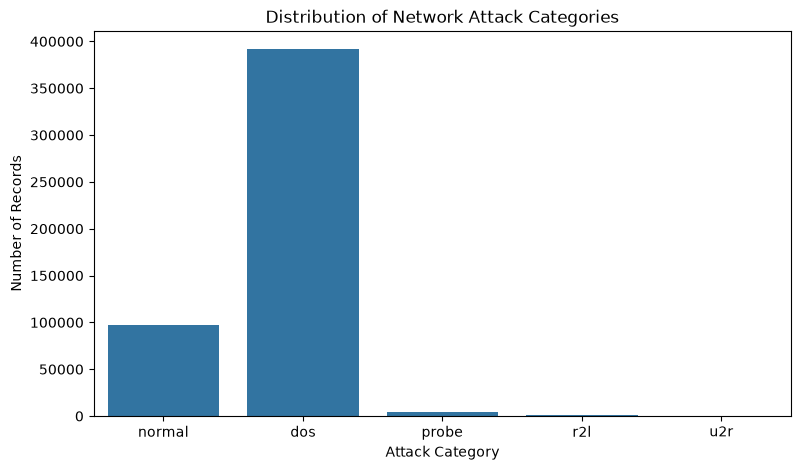

In [16]:
# 2.3 - Class Distribution Analysis

class_distribution = df["attack_category"].value_counts()

class_percentage = (
    df["attack_category"].value_counts(normalize=True) * 100
)

class_summary = pd.DataFrame({
    "Count": class_distribution,
    "Percentage (%)": class_percentage.round(3)
})

display(class_summary)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="attack_category",
    order=["normal", "dos", "probe", "r2l", "u2r"]
)

plt.title("Distribution of Network Attack Categories")
plt.xlabel("Attack Category")
plt.ylabel("Number of Records")
plt.show()

# Phase 3 — Data Cleaning

Step 3.1 — Clean Missing & Infinite Values

In [17]:
# Phase 3 - Data Cleaning

# Replace infinite values with NaN
X_clean = X.replace([np.inf, -np.inf], np.nan)

# Remove rows containing missing values
valid_rows = X_clean.notna().all(axis=1)

X_clean = X_clean.loc[valid_rows].copy()
y_clean = y.loc[valid_rows].copy()

print("Records after cleaning:", len(X_clean))

Records after cleaning: 494021


Step 3.2 — Remove Exact Duplicates

In [18]:
# Remove duplicates based on features + target

data_clean = X_clean.copy()
data_clean["multiclass_target"] = y_clean["multiclass_target"]

data_clean = data_clean.drop_duplicates()

X_clean = data_clean.drop(columns="multiclass_target")
y_clean = data_clean[["multiclass_target"]]

print("Final dataset shape:", X_clean.shape)
print("\nClass distribution:")
print(y_clean["multiclass_target"].value_counts().sort_index())

Final dataset shape: (145585, 41)

Class distribution:
multiclass_target
0    87832
1    54572
2     2130
3      999
4       52
Name: count, dtype: int64


# Phase 4 — Train/Test Split

Step 4.1 — Split Dataset

In [19]:
# Phase 4 - Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_clean["multiclass_target"]
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (116468, 41)
X_test: (29117, 41)
y_train: (116468, 1)
y_test: (29117, 1)


Step 4.2 — Verify Class Distribution

In [20]:
print("Train classes:")
print(y_train["multiclass_target"].value_counts().sort_index())

print("\nTest classes:")
print(y_test["multiclass_target"].value_counts().sort_index())

Train classes:
multiclass_target
0    70266
1    43657
2     1704
3      799
4       42
Name: count, dtype: int64

Test classes:
multiclass_target
0    17566
1    10915
2      426
3      200
4       10
Name: count, dtype: int64


Le jeu de données nettoyé a été divisé en deux ensembles : 80 % pour l'entraînement et 20 % pour le test. Une stratification a été appliquée afin de préserver la répartition des cinq classes.

# Phase 5 — One-Hot Encoding & Scaling

Step 5.1 — Encoding & Scaling

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify feature types
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
numerical_cols = X_train.select_dtypes(include="number").columns.tolist()

# Preprocessing pipeline
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols)
])

# Fit only on Train
X_train_encoded = preprocessor.fit_transform(X_train)

# Apply same transformations to Test
X_test_encoded = preprocessor.transform(X_test)

print("Train:", X_train_encoded.shape)
print("Test:", X_test_encoded.shape)

C:\Users\Badreddine\AppData\Local\Temp\ipykernel_8160\482302476.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include="object").columns.tolist()


Train: (116468, 117)
Test: (29117, 117)


Step 5.2 — Convert to DataFrame

In [22]:
feature_names = preprocessor.get_feature_names_out()

X_train_final = pd.DataFrame(
    X_train_encoded,
    columns=feature_names
)

X_test_final = pd.DataFrame(
    X_test_encoded,
    columns=feature_names
)

print("All numerical:",
      X_train_final.select_dtypes(exclude="number").empty)

display(X_train_final.head())

All numerical: True


,num__duration,num__src_bytes,num__dst_bytes,num__land,num__wrong_fragment,num__urgent,num__hot,num__num_failed_logins,num__logged_in,num__num_compromised,...,cat__flag_REJ,cat__flag_RSTO,cat__flag_RSTOS0,cat__flag_RSTR,cat__flag_S0,cat__flag_S1,cat__flag_S2,cat__flag_S3,cat__flag_SF,cat__flag_SH
0,-0.10756,-0.004415,-0.002052,-0.012433,-0.085373,-0.005296,-0.070332,-0.018246,1.017934,-0.008371,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.10756,-0.004566,-0.048485,-0.012433,-0.085373,-0.005296,-0.070332,-0.018246,-0.982382,-0.008371,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,-0.10756,-0.004544,-0.046144,-0.012433,-0.085373,-0.005296,-0.070332,-0.018246,-0.982382,-0.008371,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.10756,-0.004341,-0.042083,-0.012433,-0.085373,-0.005296,-0.070332,-0.018246,1.017934,-0.008371,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.10756,-0.004566,-0.048485,-0.012433,-0.085373,-0.005296,-0.070332,-0.018246,-0.982382,-0.008371,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


# Phase 6 — Export CSV & Save Preprocessor

Phase 6 - Export Final Data

In [23]:
# Phase 6 - Export Final Data

X_train_final.to_csv(OUTPUT / "x_train.csv", index=False)
X_test_final.to_csv(OUTPUT / "x_test.csv", index=False)

y_train.to_csv(OUTPUT / "y_train.csv", index=False)
y_test.to_csv(OUTPUT / "y_test.csv", index=False)

# Save preprocessing pipeline
joblib.dump(preprocessor, OUTPUT / "preprocessor.joblib")

print("All files exported successfully!")
print("X_train:", X_train_final.shape)
print("X_test:", X_test_final.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

All files exported successfully!
X_train: (116468, 117)
X_test: (29117, 117)
y_train: (116468, 1)
y_test: (29117, 1)
